# 1. Exploratory data analysis

First look at the dataset: size, types, class balance, distributions and correlations. Run `python scripts/download_data.py` first to download `data/students.csv`.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from preprocessing import load_data, ONE_HOT_COLUMNS

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

## Load the data

In [2]:
df = load_data("../data/students.csv")

print(df.shape)
display(df.head())
df.info()

(4424, 37)


,marital_status,application_mode,application_order,course,daytime_attendance,previous_qualification,previous_qualification_grade,nationality,mother_qualification,father_qualification,mother_occupation,father_occupation,admission_grade,displaced,special_needs,debtor,tuition_up_to_date,male,scholarship,age_at_enrollment,international,units_1st_credited,units_1st_enrolled,units_1st_evaluations,units_1st_approved,grade_1st,units_1st_no_evaluation,units_2nd_credited,units_2nd_enrolled,units_2nd_evaluations,units_2nd_approved,grade_2nd,units_2nd_no_evaluation,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   marital_status                4424 non-null   int64  
 1   application_mode              4424 non-null   int64  
 2   application_order             4424 non-null   int64  
 3   course                        4424 non-null   int64  
 4   daytime_attendance            4424 non-null   int64  
 5   previous_qualification        4424 non-null   int64  
 6   previous_qualification_grade  4424 non-null   float64
 7   nationality                   4424 non-null   int64  
 8   mother_qualification          4424 non-null   int64  
 9   father_qualification          4424 non-null   int64  
 10  mother_occupation             4424 non-null   int64  
 11  father_occupation             4424 non-null   int64  
 12  admission_grade               4424 non-null   float64
 13  displaced     

In [3]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
marital_status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
application_mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
application_order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
daytime_attendance,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
previous_qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
previous_qualification_grade,4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
nationality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
mother_qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
father_qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


## Target distribution

Three classes: `Dropout`, `Enrolled` (still enrolled at the end of the normal course duration) and `Graduate`.The classes are imbalanced, so macro-averaged F1 is used alongside accuracy in the classification notebook.

In [4]:
display(pd.DataFrame({
    "count": df["target"].value_counts(),
    "share": df["target"].value_counts(normalize=True).round(3),
}))

,count,share
target,,
Graduate,2209,0.499
Dropout,1421,0.321
Enrolled,794,0.179


## Distributions of the numeric variables

Categorical variables stored as integer codes are left out of the histograms and the correlation matrix.

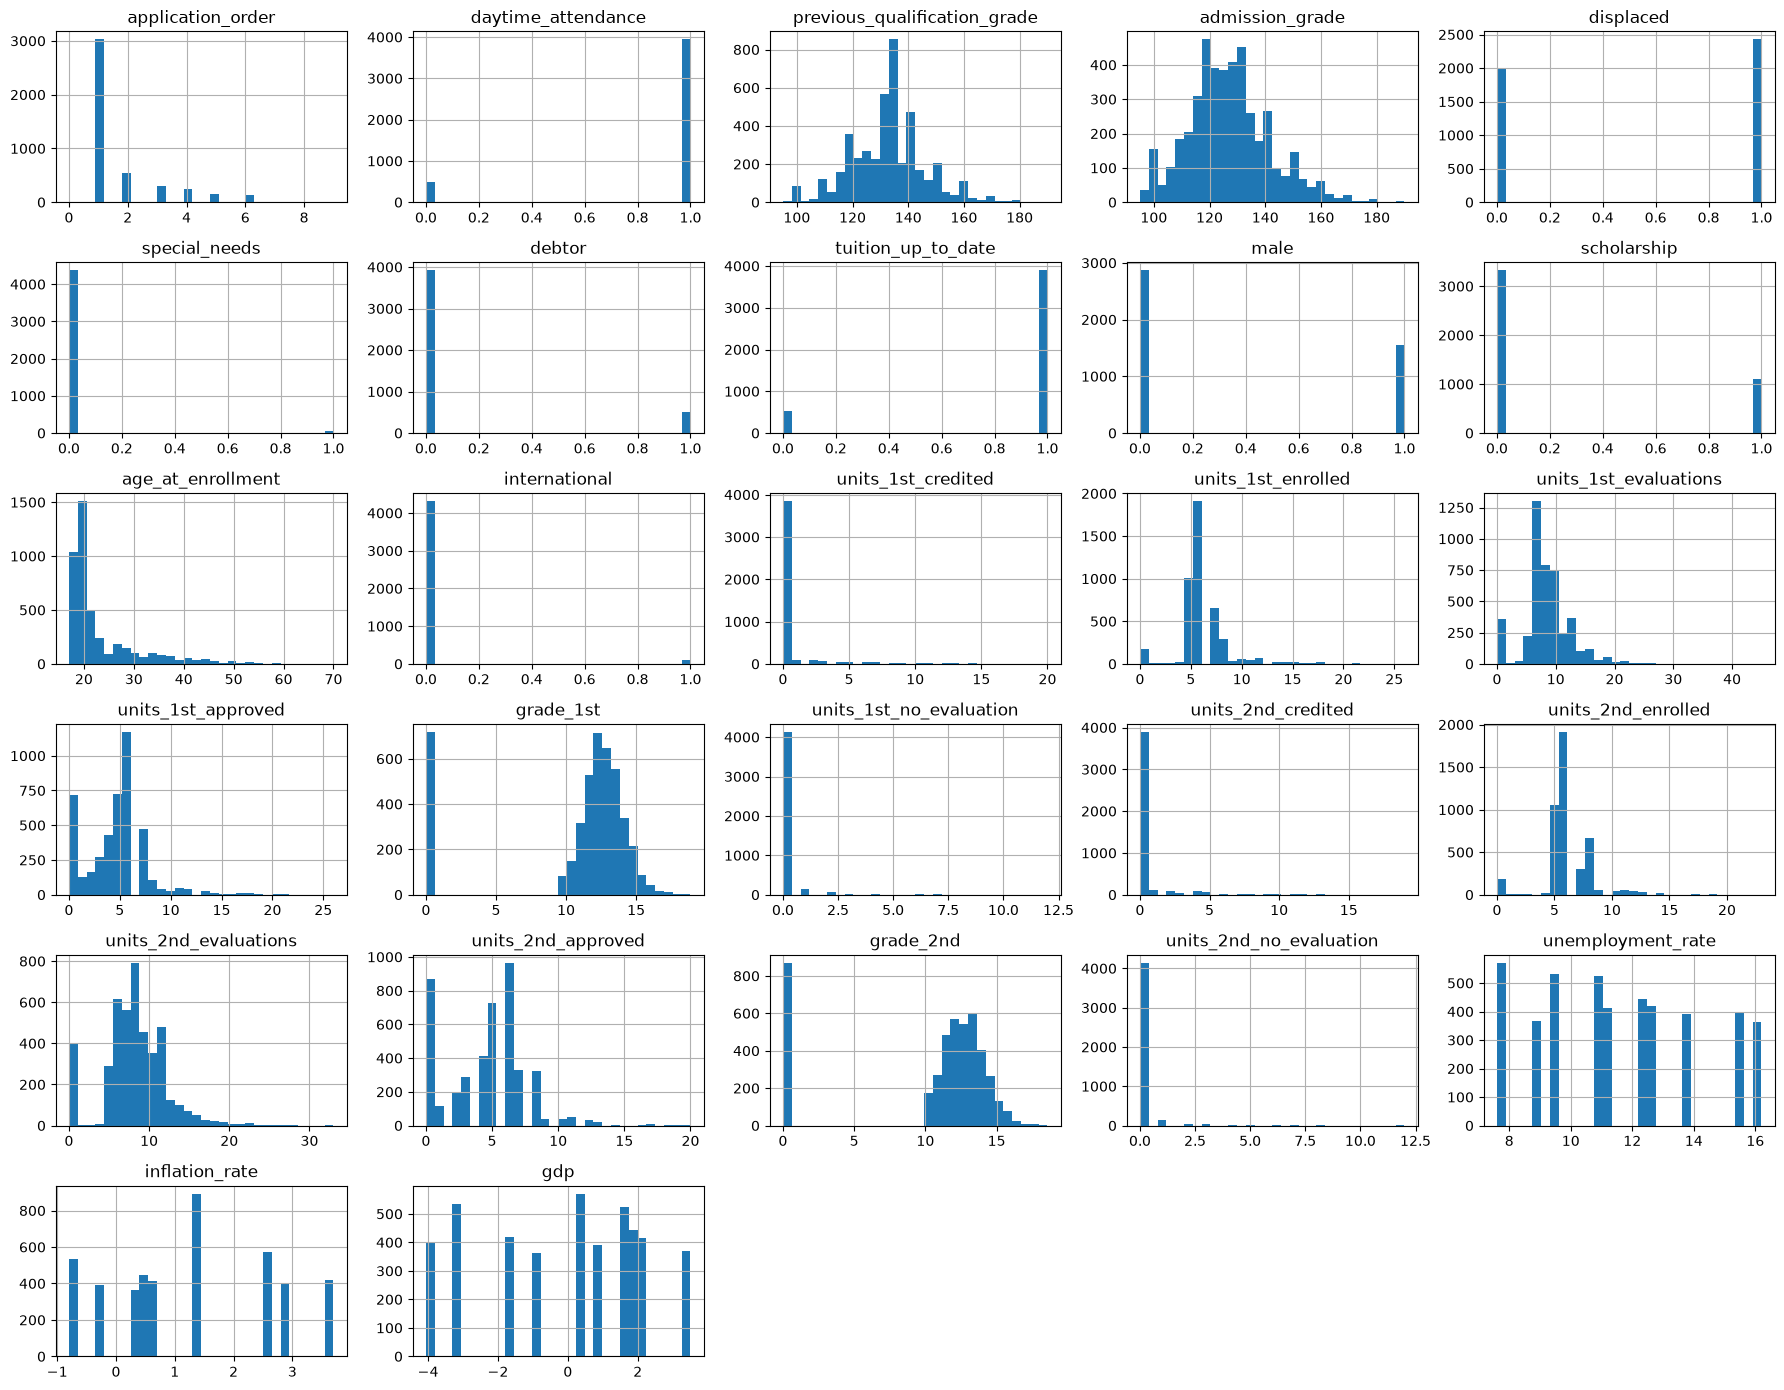

In [5]:
code_columns = ONE_HOT_COLUMNS + ["nationality"]
numeric = df.select_dtypes(include="number").drop(columns=code_columns)

numeric.hist(figsize=(18, 14), bins=30)
plt.tight_layout()
plt.show()

## Academic variables by outcome

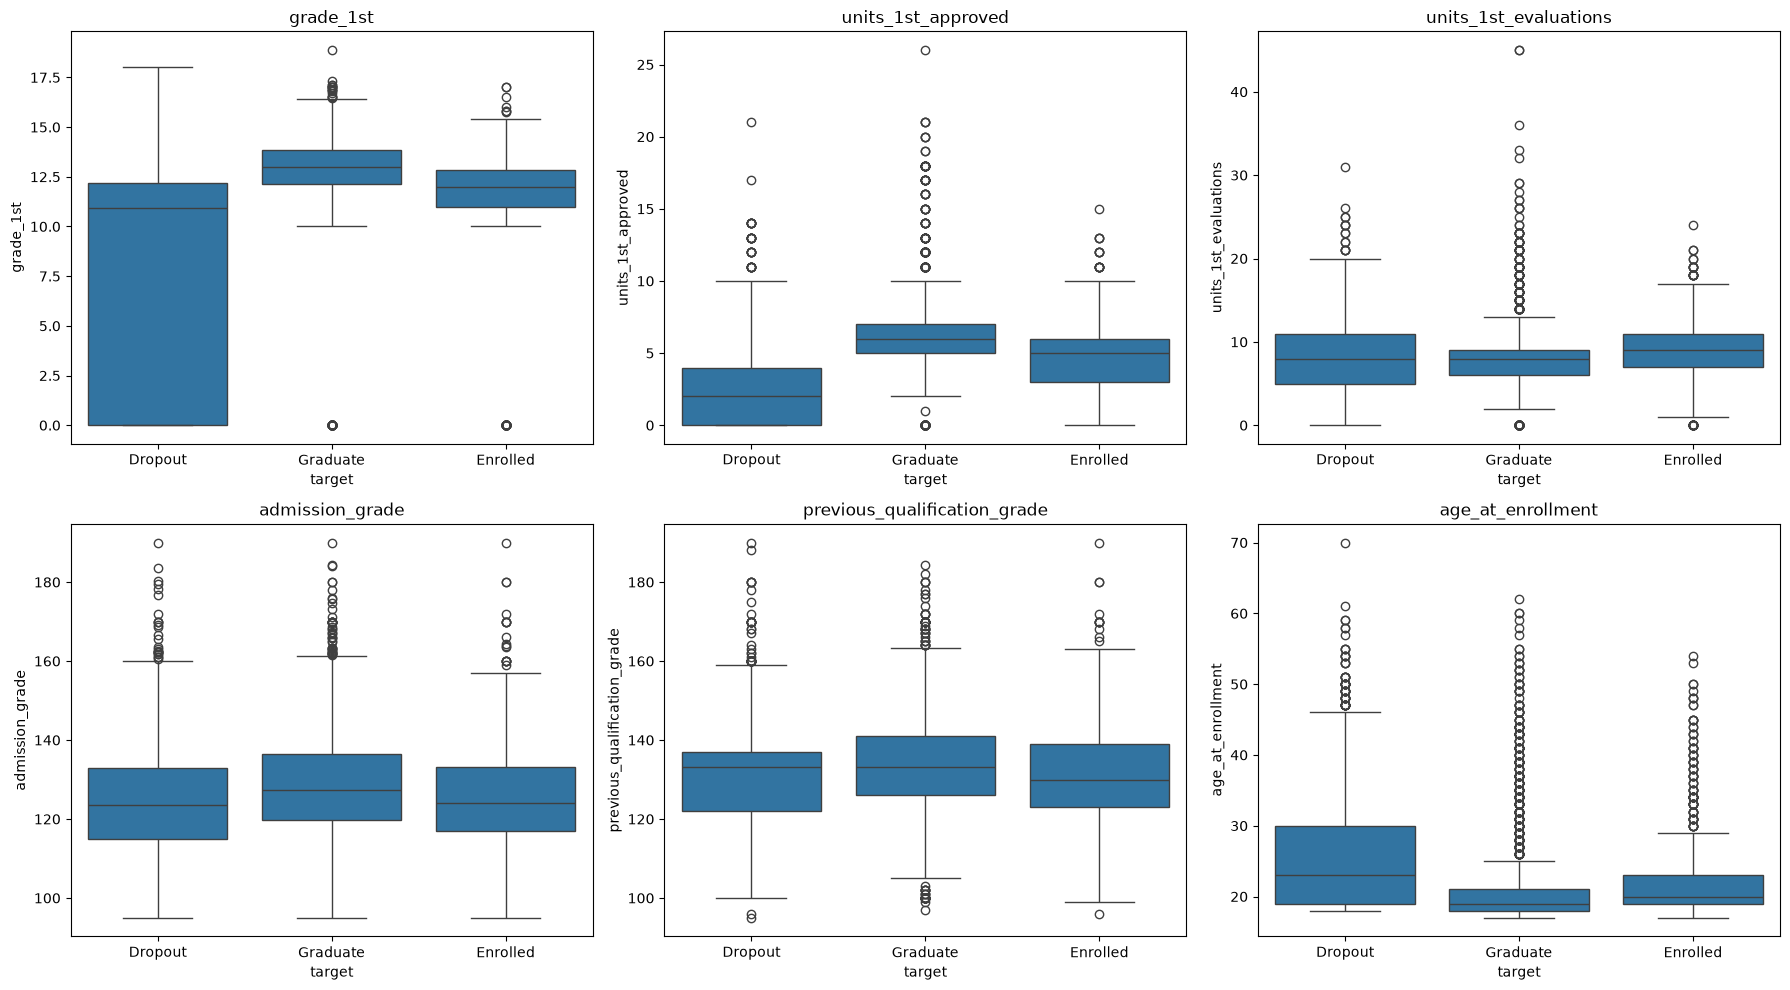

In [6]:
boxplot_vars = ["grade_1st", "units_1st_approved", "units_1st_evaluations",
                "admission_grade", "previous_qualification_grade", "age_at_enrollment"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, var in zip(axes.flatten(), boxplot_vars):
    sns.boxplot(x="target", y=var, data=df, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

## Correlation matrix

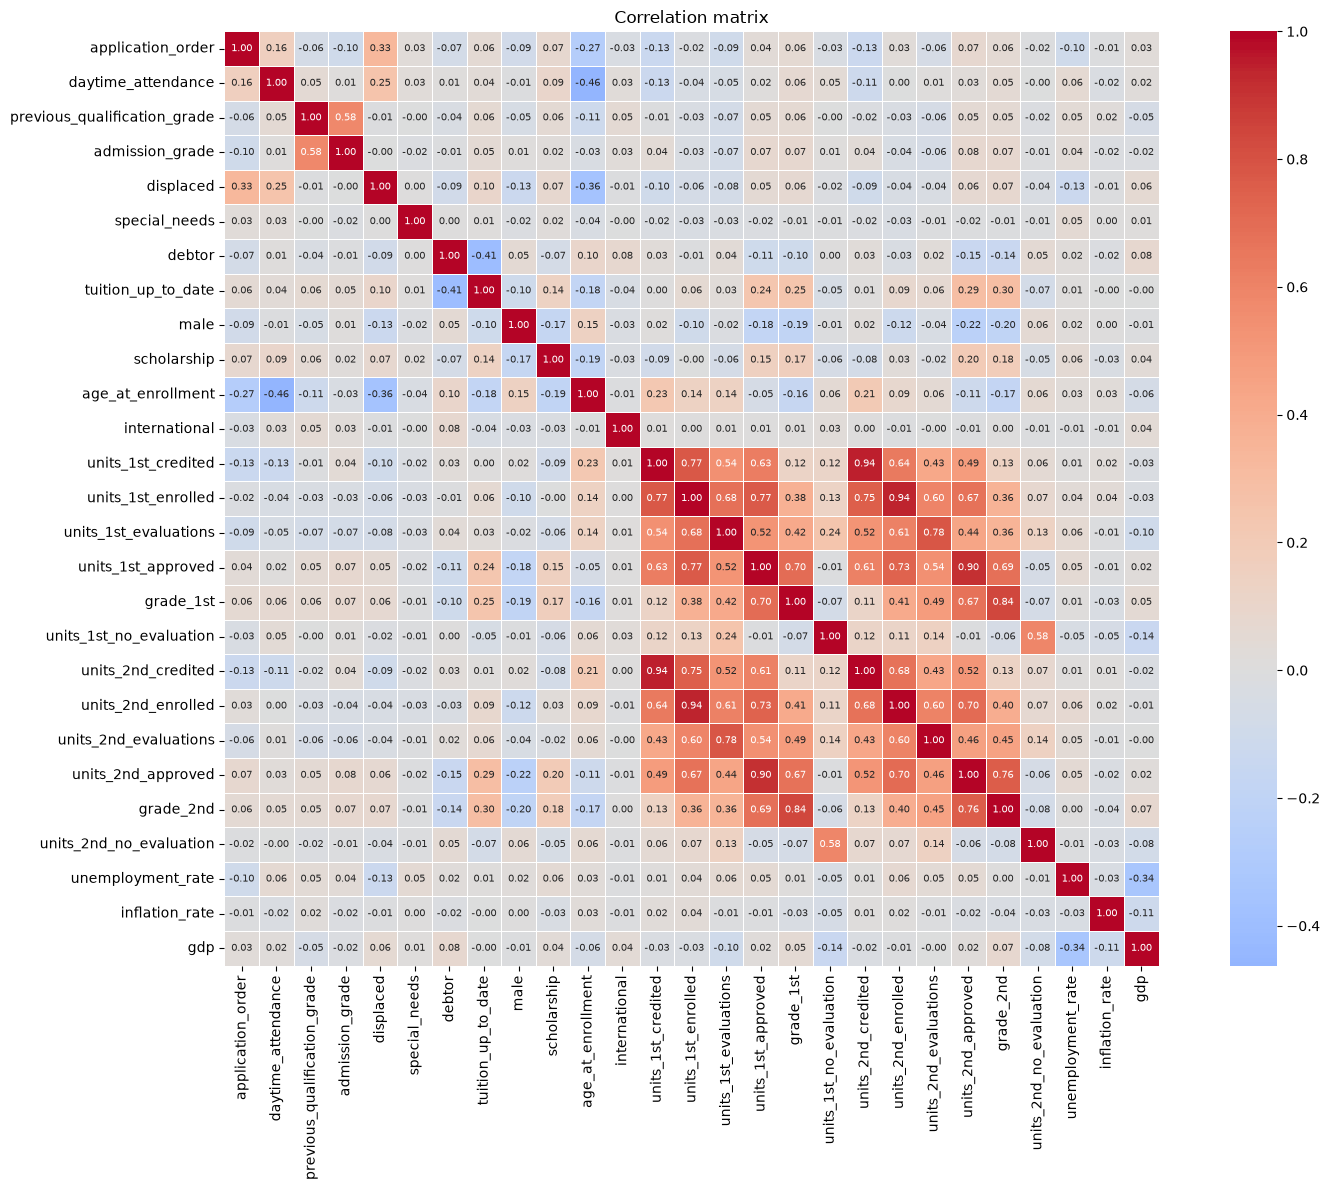

In [7]:
corr = numeric.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## Categorical variables vs outcome

Share of each outcome within every category.

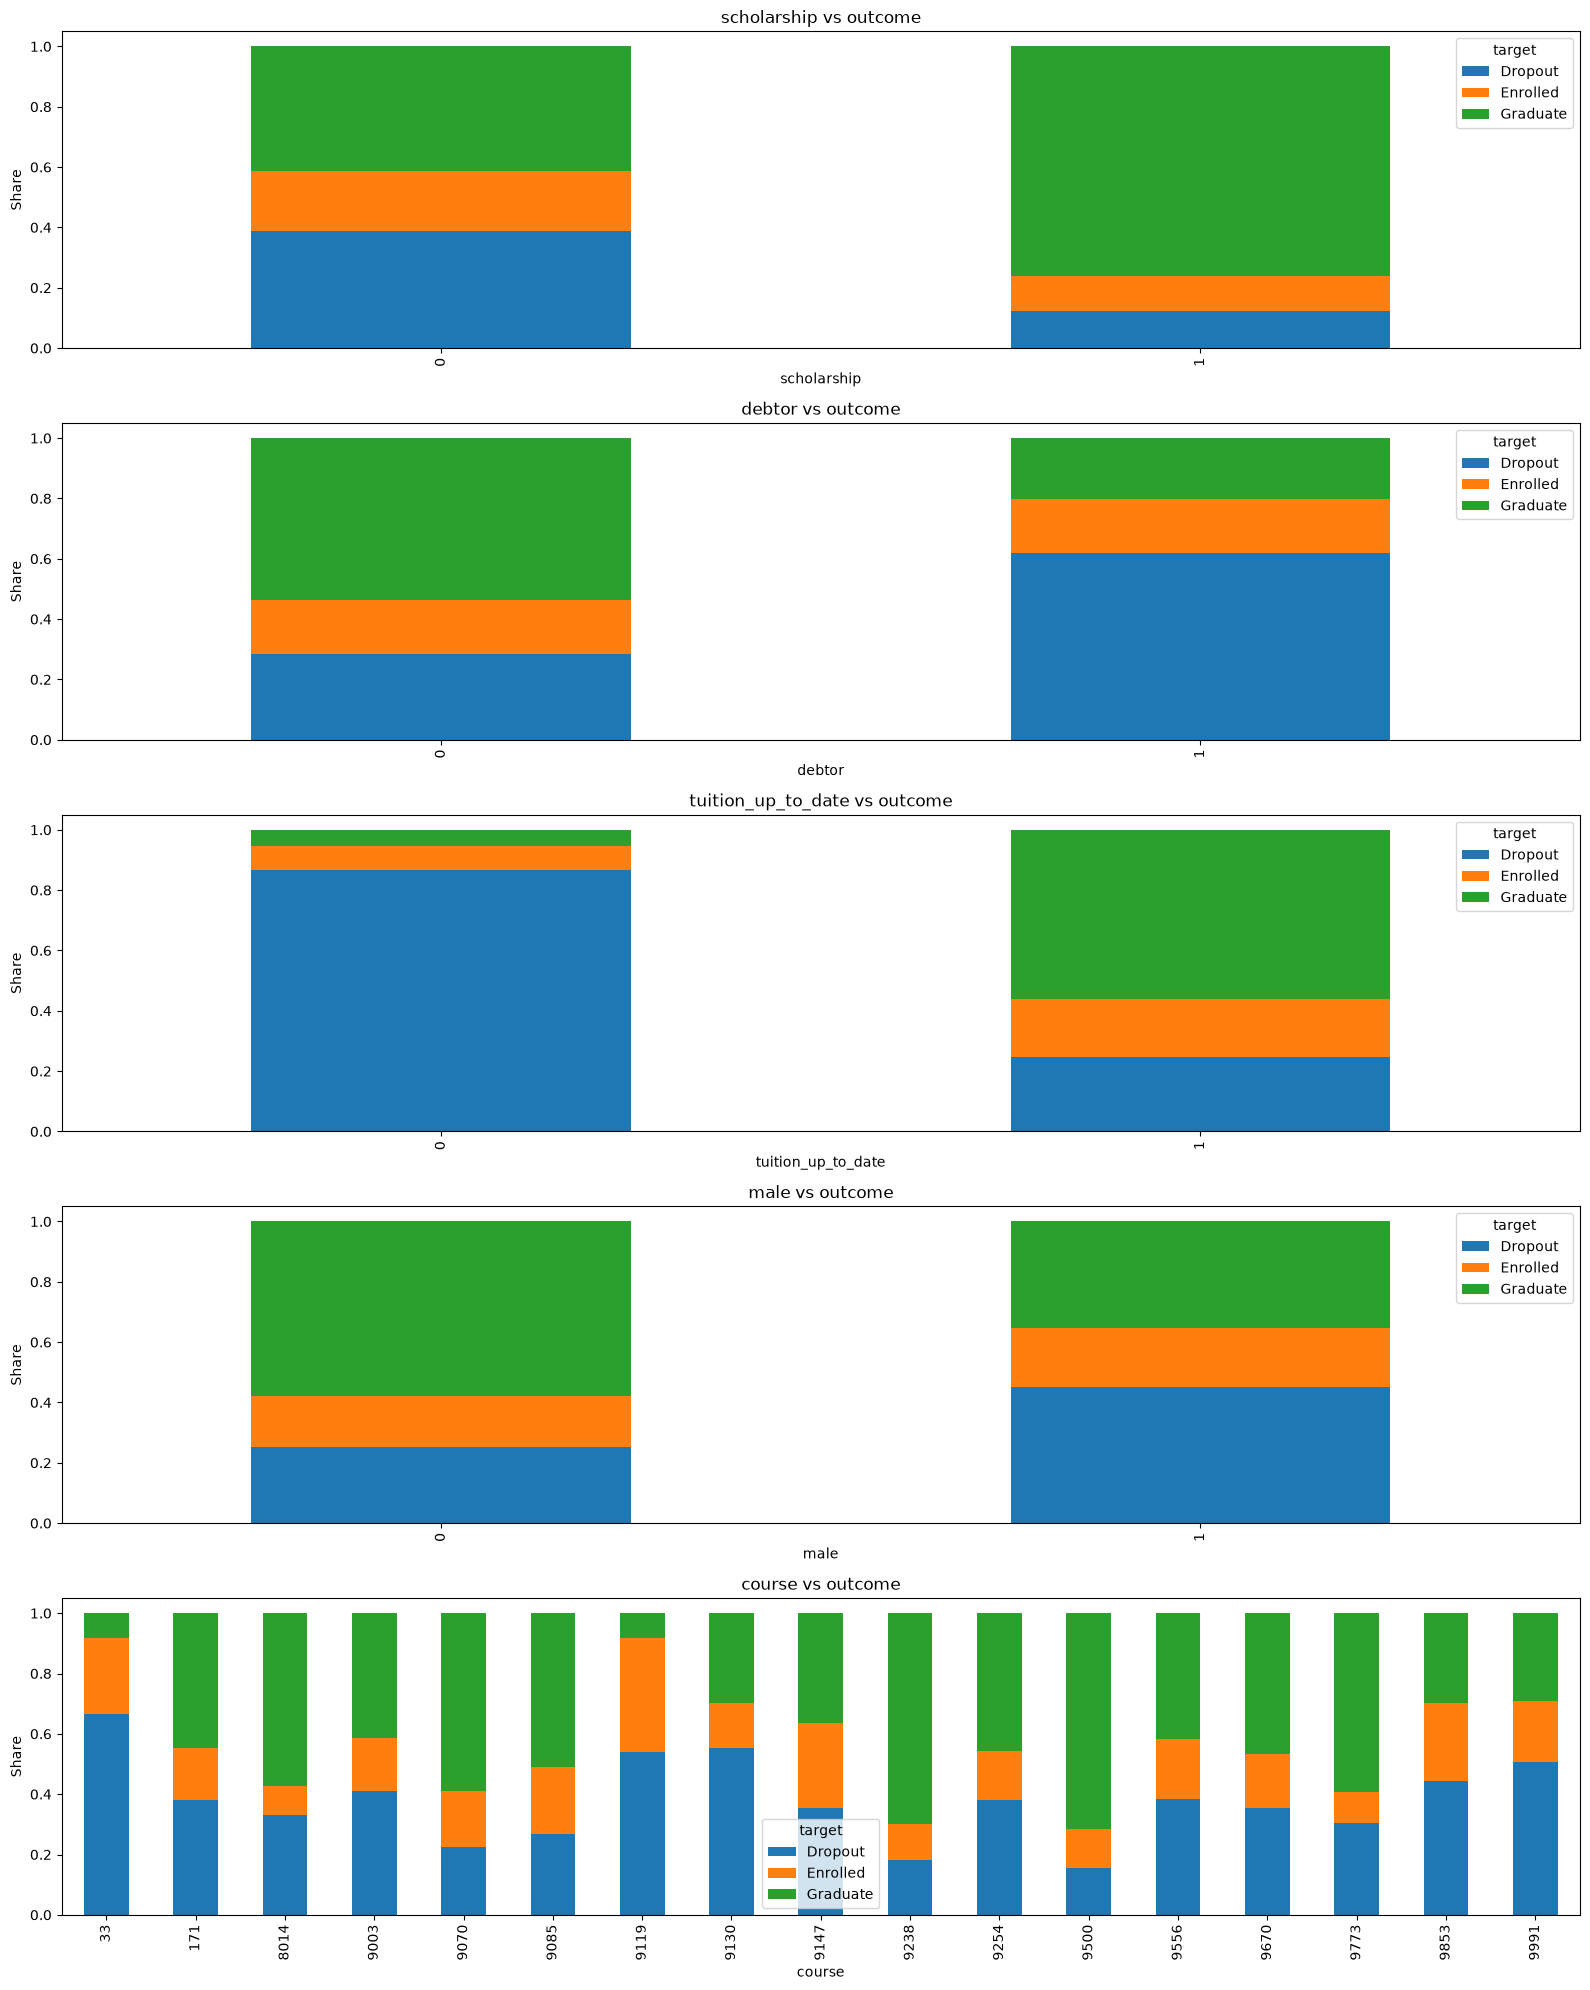

In [8]:
cat_vars = ["scholarship", "debtor", "tuition_up_to_date", "male", "course"]

fig, axes = plt.subplots(len(cat_vars), 1, figsize=(16, 4 * len(cat_vars)))
for ax, var in zip(axes, cat_vars):
    pd.crosstab(df[var], df["target"], normalize="index").plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{var} vs outcome")
    ax.set_ylabel("Share")
    ax.legend(title="target")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()